# Manual velocity start, with sampled or fixed inclination

Enter a starting **deprojected asymptotic velocity $V_\infty$** and an inclination in degrees. This uses the same rotation-only image/R/C model as `rotation_only.ipynb`.

- `FIX_INCLINATION = False`: `I_START_DEG` is only a starting value. Inclination is sampled using the saved parent run's prior.
- `FIX_INCLINATION = True`: inclination is held **exactly at `I_START_DEG`** throughout MCMC. Velocity and the other parameters remain free. Its corner plot excludes inclination; reported errors are conditional on the chosen angle and do not include inclination uncertainty.

A saved **V_rot broad candidate search** supplies the other starting parameters and frozen comparison weights. No new candidate search or PySersic fit runs here. Fixed-i runs use a separate `_fixedi` folder; changing the angle also creates a separate run. Inspect the starting residual, then run MCMC.

In [17]:
%matplotlib inline
import os
from pathlib import Path
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from importlib import reload
from dingo import three_file, manual_start, three_file_export
reload(three_file)
reload(three_file_export)
reload(manual_start)

SOURCE_ID = 15665
V_START_KMS = 450      # Example starting V_inf, not V sin(i) or V at a finite radius.
I_START_DEG = 30.0      # Fixed value if FIX_INCLINATION=True; starting value otherwise.
FIX_INCLINATION = True  # True: hold i exactly fixed. False: sample i with the parent prior.
PARENT_RUN = "rotation_v_i5_v1"
BASE_CANDIDATE = None   # None: highest-scoring saved candidate for the OTHER starting parameters.
RUN_LABEL = "manual_v1" # Change this to repeat the same V/i as a separate experiment.
WORKING_DIR = Path("/home/aakavan/kinematics/working/manual_starts")

RUN_MCMC = True         # Run/resume MCMC; False only reviews saved results.
OVERRIDE = False       # True: reset only THIS manual experiment when preparing below.
WARMUP = 1000
DRAWS = 8000
WALKERS = 64

START = dict(source_id=SOURCE_ID, parent_run=PARENT_RUN,
             start_velocity_kms=V_START_KMS, start_inclination_deg=I_START_DEG,
             base_candidate_id=BASE_CANDIDATE, run_label=RUN_LABEL,
             fix_inclination=FIX_INCLINATION)
SAMPLING = dict(warmup=WARMUP, samples=DRAWS, walkers=WALKERS, device="cuda")
FINAL_ROOT = manual_start.final_root(WORKING_DIR, **START)
print("Final NPZ, plots and run_info.txt:", FINAL_ROOT / f"ID{SOURCE_ID}")
print(f"MCMC enabled: {RUN_MCMC}; {WARMUP:,} warmup + {DRAWS:,} retained steps per walker.")
print(f"Inclination: fixed at {I_START_DEG:g} degrees" if FIX_INCLINATION
      else f"Inclination: sampled, starting at {I_START_DEG:g} degrees with the saved parent prior.")


Final NPZ, plots and run_info.txt: /home/aakavan/kinematics/working/manual_starts/rotation_v_i5_v1_manual_v1_v450_i30_cbest_fixedi/ID15665
MCMC enabled: True; 1,000 warmup + 8,000 retained steps per walker.
Inclination: fixed at 30 degrees


### 1. Inspect the exact starting fit

Center, orientation, turnover radius, R/C registration and noise scale start from the selected parent candidate. The residual below is freshly calculated at your entered V and i, **before any optimization or MCMC**. In fixed-i mode the angle stays there while the remaining parameters are sampled. A changed geometry can initially fit poorly; inspect the final residual as well.

ID15665: manual starting V_inf=450 km/s, i=30°. Inclination is FIXED; V_inf and the other parameters remain free.
The parent inclination prior is replaced by an exact fixed angle. Velocity errors exclude uncertainty in that angle.
Rendering the exact starting residual; no optimization or MCMC in this cell.
Progress and checkpoints: /home/aakavan/kinematics/results/three_file_sources/ID15665/rotation_v_i5_v1_manual_v1_v450_i30_cbest_fixedi


17:51:17 | [SharedComparisonFitter] using coordinate unit = pix
17:51:18 | [SharedComparisonFitter] image.R.cutout derived as (-121, 21, 81, 81) from summary.r_fit=40 and z=1.1613 (an explicit cutout would go stale if z were corrected)
17:51:18 | [SharedComparisonFitter] image.C.cutout derived as (44, -76, 81, 81) from summary.r_fit=40 and z=1.1613 (an explicit cutout would go stale if z were corrected)
17:51:18 | ID15665: manual V_inf=450 km/s; inclination FIXED at 30 deg; other starts from candidate 0.
17:51:18 | Inclination is fixed exactly at the supplied value and is not sampled. V_inf and the other original parameters remain free. Initialization uses the supplied V_inf and the recorded parent candidate's other parameters, without optimization. The parent's imaging inclination prior is recorded but not applied. Velocity intervals are conditional on this fixed inclination and exclude inclination uncertainty; inspect convergence and compare fixed inclinations and independent starts 

,Vinf_kms,inclination_deg,Vinf_sin_i_kms,log_likelihood,log_prior
candidate,,,,,
0,450.0,30.0,225.0,10600.772426,-1.645379


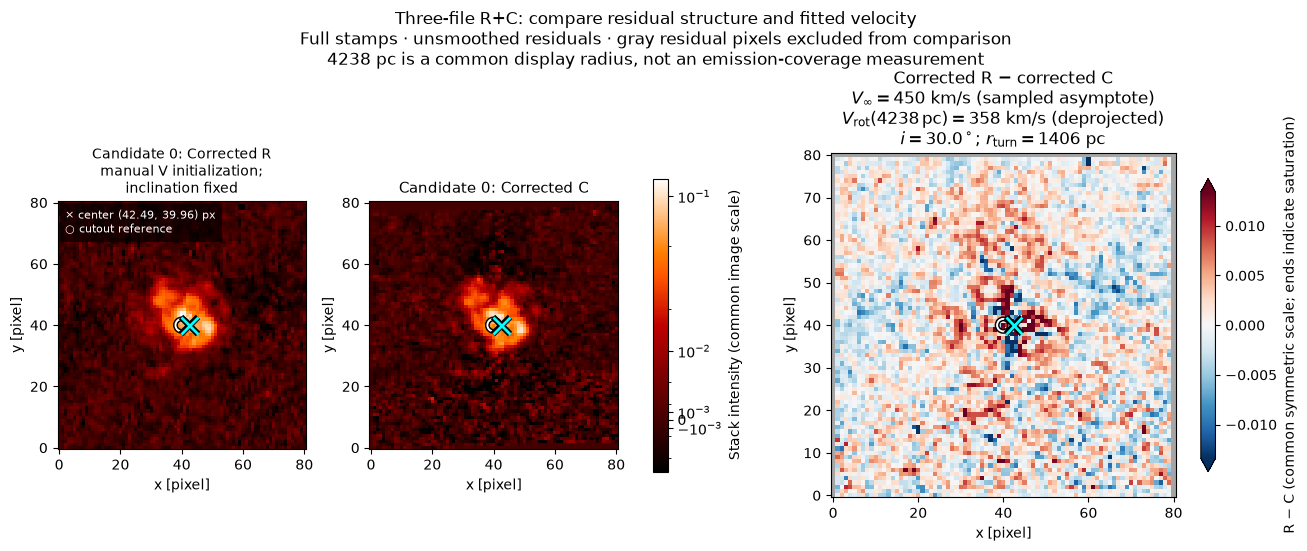

In [18]:
start = None
if RUN_MCMC:
    start = manual_start.prepare(**START, **SAMPLING, override=OVERRIDE)
else:
    try:
        start = manual_start.load_start(**START)
    except FileNotFoundError:
        print("No saved starting fit for these settings; RUN_MCMC=False does not create one.")

if start is not None:
    print("Other starting parameters from parent candidate:", start.report["base_candidate_id"])
    prior = start.report["inclination_prior"]
    if prior["type"] == "fixed":
        print(f"Inclination FIXED at {start.report['fixed_inclination_deg']:g} degrees; "
              "no inclination uncertainty is sampled.")
    elif prior["type"] == "gaussian":
        print(f"Unchanged inclination prior: {np.rad2deg(prior['mu']):.2f} ± "
              f"{np.rad2deg(prior['sigma']):.2f} degrees (1 sigma before truncation).")
    else:
        print("Unchanged inclination prior:", prior)
    display(start.table()[["Vinf_kms", "inclination_deg", "Vinf_sin_i_kms",
                           "log_likelihood", "log_prior"]])
    fig = start.figure(candidate_ids=[0])
    display(fig)
    plt.close(fig)

### 2. Run or resume MCMC

Walkers start with a small spread in velocity and the other free parameters. **Fixed-i mode has no inclination spread or inclination proposals.** Sampled-i mode retains the parent's Gaussian prior. Both use the existing emcee sampler with a batched PyTorch likelihood on the GPU, progress every 25 steps and checkpoints every 50.

Rerunning resumes a checkpoint. To restart this experiment, set `OVERRIDE=True` and rerun the preparation cell. Other fixed angles and free-i runs are preserved. For a timing test, try `WARMUP=200`, `DRAWS=500`; such a short run may not provide reliable errors. Set `RUN_MCMC=False` to review saved results without fitting.

In [19]:
result = None
if RUN_MCMC:
    result = manual_start.fit(**START, **SAMPLING, override=False)
else:
    try:
        result = manual_start.load(**START)
    except FileNotFoundError:
        print("No saved posterior for these exact settings; no MCMC was started.")

if result is not None:
    print(result.status)
    print("MCMC samples are saved. The next cell displays and exports these saved results.")

ID15665: manual starting V_inf=450 km/s, i=30°. Inclination is FIXED; V_inf and the other parameters remain free.
The parent inclination prior is replaced by an exact fixed angle. Velocity errors exclude uncertainty in that angle.
64 walkers × 1,000 warmup + 8,000 retained steps. An existing checkpoint resumes where it stopped.
Progress and checkpoints: /home/aakavan/kinematics/results/three_file_sources/ID15665/rotation_v_i5_v1_manual_v1_v450_i30_cbest_fixedi
17:51:21 | ID15665: manual V_inf=450 km/s; inclination FIXED at 30 deg; other starts from candidate 0.
17:51:21 | Inclination is fixed exactly at the supplied value and is not sampled. V_inf and the other original parameters remain free. Initialization uses the supplied V_inf and the recorded parent candidate's other parameters, without optimization. The parent's imaging inclination prior is recorded but not applied. Velocity intervals are conditional on this fixed inclination and exclude inclination uncertainty; inspect converge

### 3. Inspect and export saved results

Residual maps show the saved maximum-posterior fit. Corner titles summarize retained draws. With inclination fixed, its panel is omitted and velocity errors are **conditional on that exact angle**. Compare residuals, traces and sampling checks across fixed angles before interpreting differences.

This cell never starts MCMC. It saves the final NPZ, plots and run_info.txt from the existing chain. If the original PySersic files have changed or are unavailable, their plots are omitted and the reason is recorded.

ID15665 | three-file DINGO | complete
64 ensemble walkers × 8000 retained steps; σ₀ = 0.
Manual start: V_inf=450 km/s, i=30°; V_inf sampled; i fixed. Other initial values from parent candidate 0.
Fixed i = 30°; intervals are conditional on this inclination.
Sampling-length checks passed; errors use the approximate stacked-image noise model.
/home/aakavan/kinematics/results/three_file_sources/ID15665/rotation_v_i5_v1_manual_v1_v450_i30_cbest_fixedi
Initial V_inf=450 km/s
Inclination FIXED at 30 degrees; velocity intervals exclude inclination uncertainty.


,median,minus_1sigma,plus_1sigma
parameter,,,
Vinf [km/s],406.545022,4.393820,5.226170
Vrot(4238 pc) [km/s],321.766366,2.428587,3.017019
Vrot(4238 pc) sin(i) [km/s],160.883187,1.214293,1.508509
Vinf sin(i) [km/s],203.272516,2.196910,2.613085


,parameter,autocorrelation_steps,retained_steps_per_autocorrelation,effective_samples,split_half_shift
0,velocity.V_rot,57.578433,138.940911,8892.218333,0.049010
1,velocity.R_v,74.739553,107.038370,6850.455698,0.060773
2,velocity.x0_v,82.252915,97.260991,6224.703404,0.048739
3,velocity.y0_v,81.658333,97.969181,6270.027576,0.005047
4,velocity.theta_v,93.271152,85.771429,5489.371440,0.062075
5,image.R.dx,51.646349,154.899623,9913.575878,0.002916
6,image.R.dy,41.602460,192.296319,12306.964444,0.050304
7,noise.ln_f,37.160658,215.281442,13778.012270,0.018332


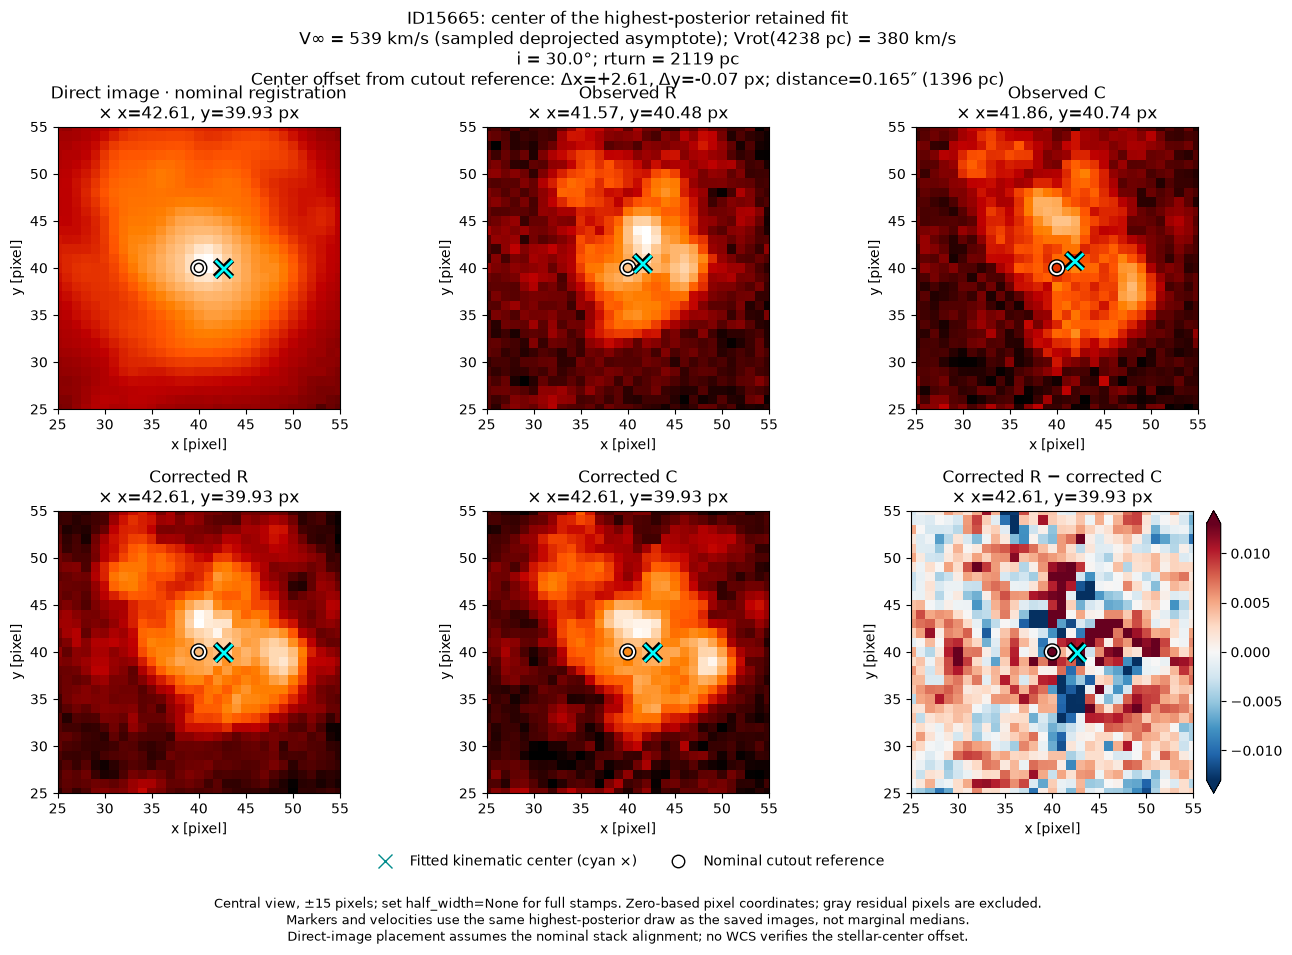

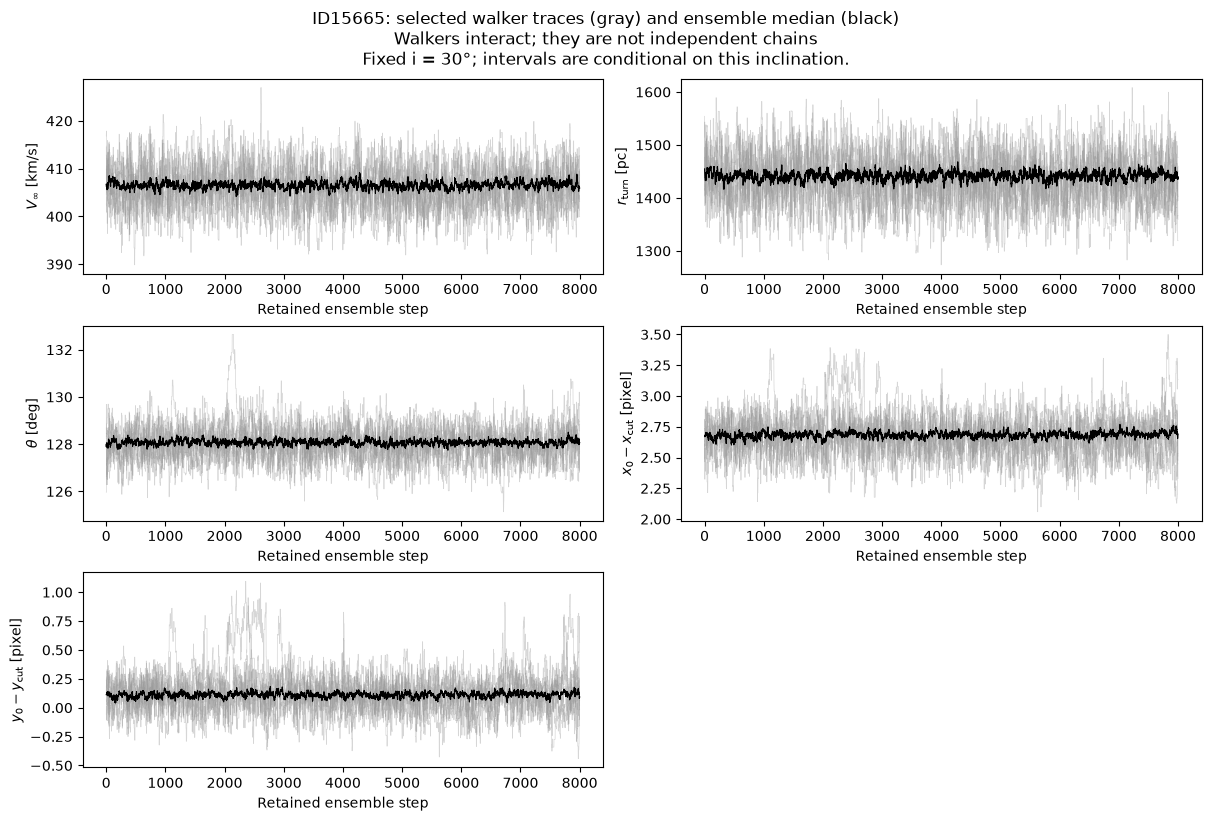

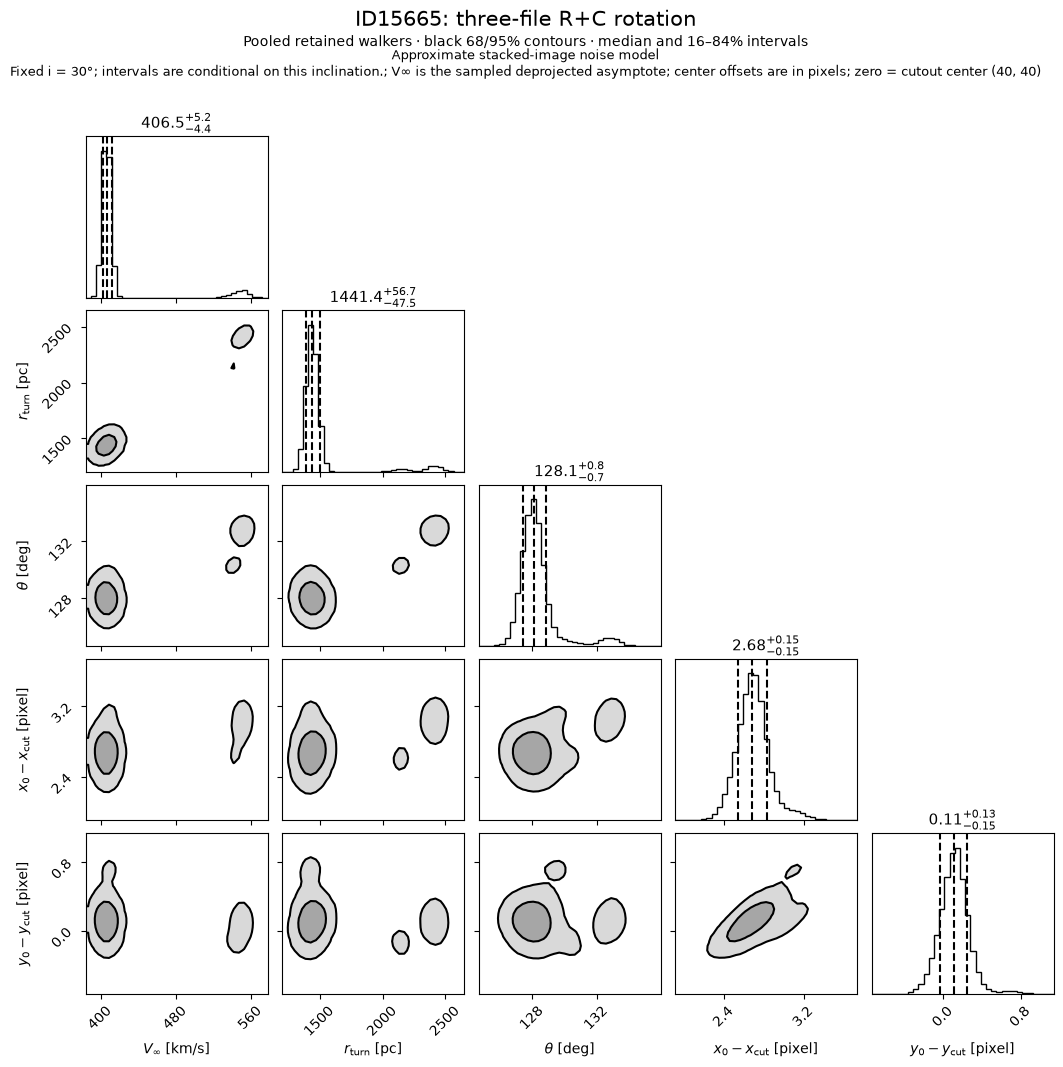

Saving final results and plots to /home/aakavan/kinematics/working/manual_starts/rotation_v_i5_v1_manual_v1_v450_i30_cbest_fixedi/ID15665
Final files: /home/aakavan/kinematics/working/manual_starts/rotation_v_i5_v1_manual_v1_v450_i30_cbest_fixedi/ID15665 (12 files)
Final files: /home/aakavan/kinematics/working/manual_starts/rotation_v_i5_v1_manual_v1_v450_i30_cbest_fixedi/ID15665


In [20]:
from dingo.three_file_center_plot import review_center
from dingo import three_file_export
from importlib import reload
reload(three_file_export)  # Use export fixes in an already-running kernel.

result = None
try:
    result = manual_start.load(**START)
except FileNotFoundError:
    print("No saved posterior yet. Run MCMC above, or select a completed start in settings.")

if result is not None:
    print(result.status)
    print(f"Initial V_inf={result.report['start_velocity_kms']:g} km/s")
    if result.report.get("inclination_mode") == "fixed":
        print(f"Inclination FIXED at {result.report['fixed_inclination_deg']:g} degrees; "
              "velocity intervals exclude inclination uncertainty.")
    else:
        print(f"Starting i={result.report['start_inclination_deg']:g} degrees; inclination sampled.")
    display(result.velocity_summary())
    display(result.diagnostics())
    for make_plot in (lambda: review_center(result, half_width=15.),
                      result.traces, result.corner):
        fig = make_plot()
        display(fig)
        plt.close(fig)

if result is not None and result.report["status"] == "complete":
    final_directory = result.export(FINAL_ROOT)
    print("Final files:", final_directory)
